## Project Setup, Load، Explore، & Merging step

In [ ]:
!pip install kagglehub

In [ ]:
import kagglehub
import pandas as pd
import os

#1. Importing the first dataset directly from Kaggle
path1 = kagglehub.dataset_download("sasakitetsuya/construction-estimation-data")
csv1 = next(f for f in os.listdir(path1) if f.endswith(".csv"))
df_est = pd.read_csv(os.path.join(path1, csv1))

# 2. Importing the second dataset directly from Kagglepath2 = kagglehub.dataset_download("ziya07/engineering-project-cost-feasibility-dataset")
csv2 = next(f for f in os.listdir(path2) if f.endswith(".csv"))
df_feas = pd.read_csv(os.path.join(path2, csv2))

# 3. عرض أسماء الأعمدة في كل جدول
print("✅ Dataset 1 Loaded! Shape:", df_est.shape)
print("📋 Columns in Dataset 1:", df_est.columns.tolist())

print("\n✅ Dataset 2 Loaded! Shape:", df_feas.shape)
print("📋 Columns in Dataset 2:", df_feas.columns.tolist())


Using Colab cache for faster access to the 'construction-estimation-data' dataset.
Using Colab cache for faster access to the 'engineering-project-cost-feasibility-dataset' dataset.
✅ Dataset 1 Loaded! Shape: (1000, 6)
📋 Columns in Dataset 1: ['Material_Cost', 'Labor_Cost', 'Profit_Rate', 'Discount_or_Markup', 'Policy_Reason', 'Total_Estimate']

✅ Dataset 2 Loaded! Shape: (3245, 13)
📋 Columns in Dataset 2: ['Project_ID', 'Project_Name', 'Project_Type', 'Scope_Complexity', 'Estimated_Cost_USD', 'Resource_Allocation_Score', 'Risk_Assessment_Score', 'Environmental_Impact_Score', 'Historical_Cost_Deviation_%', 'Stakeholder_Priority_Score', 'Time_Estimate_Days', 'Feasibility_Label', 'Scope_Complexity_Numeric']


In [ ]:
import pandas as pd

PROJECT_NAME = "Price quotes for contractors"
TARGET_COLUMN = "Purchased"

# 1. Selecting useful columns from the second table (the first 1000 rows, to match the size of the first table)
selected_feas = df_feas[[
    "Project_Type",
    "Scope_Complexity",
    "Time_Estimate_Days",
    "Risk_Assessment_Score",
    "Feasibility_Label"
]].iloc[:len(df_est)].reset_index(drop=True)

# 2. دمج الجدول الأول (التسعير) مع الأعمدة المختارة من الجدول الثاني
df_est_clean = df_est.reset_index(drop=True)
df = pd.concat([df_est_clean, selected_feas], axis=1)

# 3. تحويل عمود الجدوى (Feasibility_Label) إلى عمود الهدف الثنائي (0 و 1)
# نتحقق من القيم الموجودة فيه ونحولها إلى 1 (مقبول/مجدٍ) و 0 (مرفوض/غير مجدٍ)
df[TARGET_COLUMN] = df["Feasibility_Label"].apply(
    lambda x: 1 if str(x).strip().lower() in ["feasible", "1", "yes", "true", "approved", "high"] else 0
)

# حذف العمود النصي الأصلي للهدف حتى لا يتسرب إلى المدخلات (Data Leakage)
df = df.drop(columns=["Feasibility_Label"])

# 4. هندسة خصائص جديدة (نسبة تكلفة المواد إلى العمالة)
df["Material_to_Labor_Ratio"] = df["Material_Cost"] / (df["Labor_Cost"] + 1)

print("📌 Project:", PROJECT_NAME)
print("📊 Merged Dataset Shape:", df.shape)
print("\n🔍 Missing Values:\n", df.isnull().sum())
print("\n🎯 Target Distribution (Purchased):\n", df[TARGET_COLUMN].value_counts())
print("\n📋 First 5 Records:\n", df.head())
print("\n✅ Data Merging & Feature Engineering completed!")


📌 Project: Price quotes for contractors
📊 Merged Dataset Shape: (1000, 12)

🔍 Missing Values:
 Material_Cost              0
Labor_Cost                 0
Profit_Rate                0
Discount_or_Markup         0
Policy_Reason              0
Total_Estimate             0
Project_Type               0
Scope_Complexity           0
Time_Estimate_Days         0
Risk_Assessment_Score      0
Purchased                  0
Material_to_Labor_Ratio    0
dtype: int64

🎯 Target Distribution (Purchased):
 Purchased
1    582
0    418
Name: count, dtype: int64

📋 First 5 Records:
    Material_Cost  Labor_Cost  Profit_Rate  Discount_or_Markup  \
0          43985       12836           10                1095   
1          45504       17873           15               -6426   
2          33656        8401           25                9862   
3          36509        8523           20                8096   
4          37372       14123           30               -9598   

                                       Po

 The merging step was successful, and the results are excellent! We now have 1,000 rows and 12 columns with no missing values, and a very balanced distribution for the target column (582 accepted and 418 rejected).

## During the Exploratory Data Analysis (EDA) phase
#### we aim to examine descriptive statistics and the relationships between the columns and the target variable (Purchased)—both visually and numerically—before training any models.

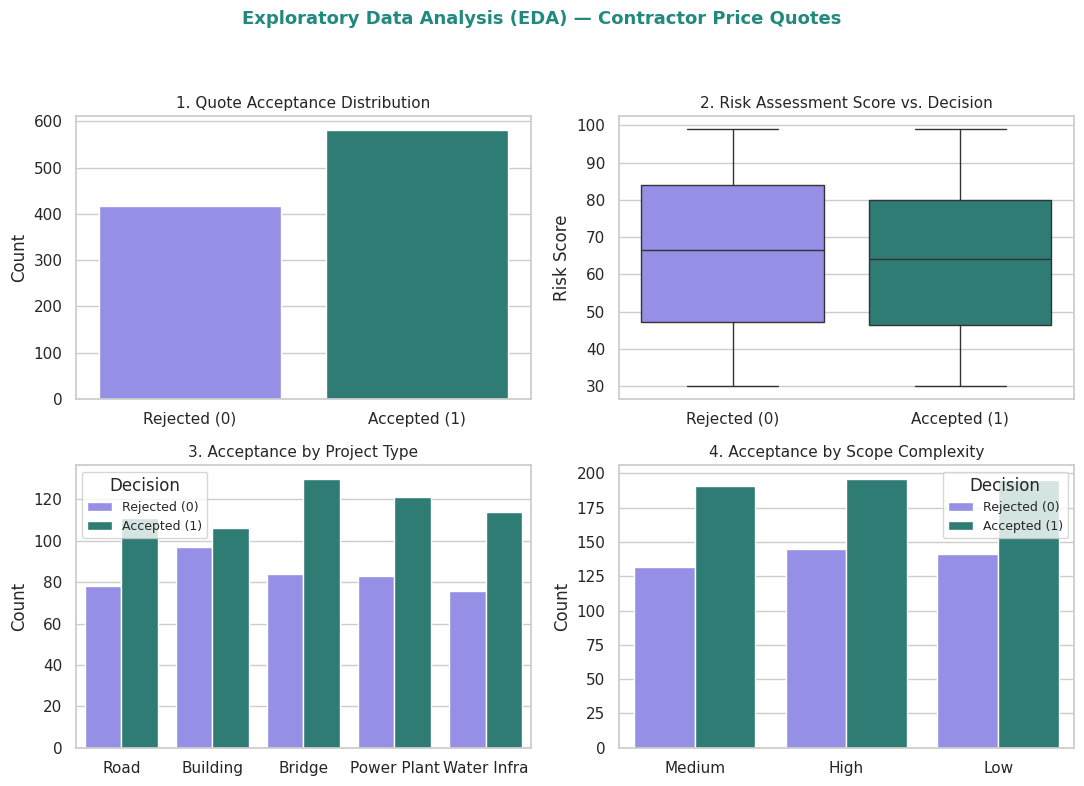

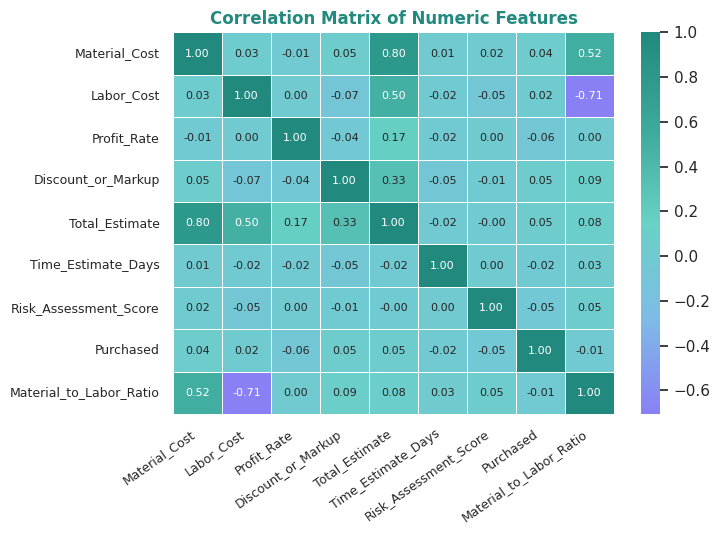

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# تعريف لوحة ألوان المشروع الخاصة بك
PROJECT_PALETTE = ["#21897e", "#3ba99c", "#69d1c5", "#7ebce6", "#8980f5"]
BINARY_PALETTE = {0: "#8980f5", 1: "#21897e"}
CUSTOM_CMAP = LinearSegmentedColormap.from_list("custom_ocean", ["#8980f5", "#7ebce6", "#69d1c5", "#3ba99c", "#21897e"])

# إعداد لوحة الرسوم البيانية وتوزيع المحاور بدون أقواس مربعة
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
ax1, ax2, ax3, ax4 = axes.flat
fig.suptitle("Exploratory Data Analysis (EDA) — Contractor Price Quotes", fontsize=13, fontweight="bold", color="#21897e")

# الرسم 1: توزيع حالات القبول والرفض
sns.countplot(
    data=df, x="Purchased", hue="Purchased",
    palette=BINARY_PALETTE, legend=False, ax=ax1
)
ax1.set_title("1. Quote Acceptance Distribution", fontsize=11)
ax1.set_xticks(list((0, 1)))
ax1.set_xticklabels(["Rejected (0)", "Accepted (1)"])
ax1.set_xlabel("")
ax1.set_ylabel("Count")

# الرسم 2: تأثير درجة المخاطر على قبول العرض
sns.boxplot(
    data=df, x="Purchased", y="Risk_Assessment_Score", hue="Purchased",
    palette=BINARY_PALETTE, legend=False, ax=ax2
)
ax2.set_title("2. Risk Assessment Score vs. Decision", fontsize=11)
ax2.set_xticks(list((0, 1)))
ax2.set_xticklabels(["Rejected (0)", "Accepted (1)"])
ax2.set_xlabel("")
ax2.set_ylabel("Risk Score")

# الرسم 3: قبول العروض حسب نوع المشروع
sns.countplot(
    data=df, x="Project_Type", hue="Purchased",
    palette=BINARY_PALETTE, ax=ax3
)
ax3.set_title("3. Acceptance by Project Type", fontsize=11)
ax3.set_xlabel("")
ax3.set_ylabel("Count")
ax3.legend(title="Decision", labels=["Rejected (0)", "Accepted (1)"], fontsize=9)

# الرسم 4: تأثير مستوى تعقيد المشروع على القرار
sns.countplot(
    data=df, x="Scope_Complexity", hue="Purchased",
    palette=BINARY_PALETTE, ax=ax4
)
ax4.set_title("4. Acceptance by Scope Complexity", fontsize=11)
ax4.set_xlabel("")
ax4.set_ylabel("Count")
ax4.legend(title="Decision", labels=["Rejected (0)", "Accepted (1)"], fontsize=9)

plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

# 5. مصفوفة الارتباط بحجم أصغر وتدرج ألوان المشروع
plt.figure(figsize=(7.5, 5.5))
numeric_df = df.select_dtypes(include=["number"])
sns.heatmap(
    numeric_df.corr(), annot=True, fmt=".2f",
    cmap=CUSTOM_CMAP, linewidths=0.5, annot_kws={"size": 8}
)
plt.title("Correlation Matrix of Numeric Features", fontsize=12, fontweight="bold", color="#21897e")
plt.xticks(fontsize=9, rotation=35, ha="right")
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()


## Data Cleaning & Preparation
#### The data cleaning and quality assessment phase (Data Cleaning & Preparation) for the merged dataframe `df`, ensuring the removal of duplicates, outliers, and illogical values, as well as the cleaning of text data.

The data cleaning and preparation phase for the merged dataframe (`df`) involves ensuring the dataset is free from duplicates, outliers, or illogical values, as well as cleaning text data.

These steps are crucial for several reasons:

• Removing duplicates (`drop_duplicates`): This ensures there are no redundant entries, which could mislead the model and cause it to "memorize" the data rather than learn from it.
• Cleaning text (`str.strip`): This removes any hidden whitespace at the beginning or end of entries in the `Project_Type` or `Scope_Complexity` columns.
• Business logic validation: This verifies that all entries have positive values ​​(greater than zero) for material costs, labor costs, and project duration.
• Consolidating `Policy_Reason` into `Policy_Category`: Long, descriptive text strings can distract machine learning models. Converting them into concise, three-word categories preserves their original meaning while preventing an unnecessary increase in the number of columns later on.

In [ ]:
# 🧹 Data Cleaning & Preparation

print("🔍 Before Cleaning Shape:", df.shape)

# 1. التحقق من الصفوف المكررة وحذفها إن وجدت
duplicates = df.duplicated().sum()
print("🔁 Duplicate Rows Found:", duplicates)
df = df.drop_duplicates().reset_index(drop=True)

# 2. التحقق من القيم المفقودة ومعالجتها (احتياطياً)
print("❓ Missing Values:\n", df.isnull().sum()[df.isnull().sum() > 0])

# 3. تنظيف الأعمدة النصية (إزالة المسافات الزائدة وتوحيد التنسيق)
text_cols = df.select_dtypes(include=["object"]).columns
for col in text_cols:
    df[col] = df[col].astype(str).str.strip()

# 4. التحقق من منطقية الأرقام (التأكد من عدم وجود تكاليف أو أيام بالسالب أو صفر)
df = df[
    (df["Material_Cost"] > 0) &
    (df["Labor_Cost"] > 0) &
    (df["Total_Estimate"] > 0) &
    (df["Time_Estimate_Days"] > 0)
].reset_index(drop=True)

# 5. تبسيط عمود Policy_Reason النصي الطويل ( يحسن دقة النموذج جداً)
# نأخذ أول 3 كلمات فقط كتصنيف مختصر بدلاً من جملة طويلة
df["Policy_Category"] = df["Policy_Reason"].apply(lambda x: " ".join(x.split()[:3]))
df = df.drop(columns=["Policy_Reason"])

print("\n✨ After Cleaning Shape:", df.shape)
print("📋 Cleaned Columns:", df.columns.tolist())
print("✅ Data Cleaning completed successfully!")

🔍 Before Cleaning Shape: (1000, 12)
🔁 Duplicate Rows Found: 0
❓ Missing Values:
 Series([], dtype: int64)

✨ After Cleaning Shape: (1000, 12)
📋 Cleaned Columns: ['Material_Cost', 'Labor_Cost', 'Profit_Rate', 'Discount_or_Markup', 'Total_Estimate', 'Project_Type', 'Scope_Complexity', 'Time_Estimate_Days', 'Risk_Assessment_Score', 'Purchased', 'Material_to_Labor_Ratio', 'Policy_Category']
✅ Data Cleaning completed successfully!


## Train / Test Split


In [ ]:
# 🚀 Step: Train / Test Split & Preprocessing (70% Train / 30% Test)

from sklearn.model_selection import train_test_split
from sklearn.compose import make_column_transformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline

# 1. فصل المدخلات (X) عن عمود الهدف (y)
X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN]

# 2. تقسيم البيانات بنسبة 70% تدريب و 30% اختبار
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# 3. تجهيز خط المعالجة التلقائي للأرقام والنصوص
prep = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
     make_column_selector(dtype_include="number")),
    (make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")),
     make_column_selector(dtype_include="object"))
)

# 4. تطبيق المعالجة على بيانات التدريب والاختبار
X_train = prep.fit_transform(X_train_raw)
X_test = prep.transform(X_test_raw)

print("📊 Total Records:", len(df))
print("📘 Training Records (70%):", X_train.shape)
print("📗 Testing Records (30%):", X_test.shape)
print("\n🎯 Training Target Distribution:\n", y_train.value_counts())
print("\n🎯 Testing Target Distribution:\n", y_test.value_counts())
print("\n✅ Train / Test Split & Preprocessing completed!")


📊 Total Records: 1000
📘 Training Records (70%): (700, 21)
📗 Testing Records (30%): (300, 21)

🎯 Training Target Distribution:
 Purchased
1    407
0    293
Name: count, dtype: int64

🎯 Testing Target Distribution:
 Purchased
1    175
0    125
Name: count, dtype: int64

✅ Train / Test Split & Preprocessing completed!


Analysis of the split results: The distribution ratios in our dataset are excellent and ideal for training, for several reasons:

• Scientific standard for imbalanced data: Data is considered "imbalanced"—requiring interventions such as SMOTE or undersampling—only when one class accounts for less than 10% to 20% of the total (e.g., 90% vs. 10%). A ratio of 58% to 42% is very close to a perfect balance (50/50) and accurately reflects the reality of the contracting market.
• Effectiveness of the `stratify=y` parameter: Note that the proportion of "accepted" cases in the training set (58.1%) is nearly identical to that in the test set (58.3%), which ensures a fair evaluation and prevents model bias.
• Sufficient sample size for each class: Having 293 instances of "rejected" cases and 407 instances of "accepted" cases in the training set provides a robust enough sample for a Gradient Boosting model to learn the patterns of each class with high accuracy and without bias.

## Feature Engineering
#### We will now apply feature engineering—following the split into `X_train_raw` and `X_test_raw` to prevent data leakage—by creating three intelligent, highly practical features tailored to the construction sector. We will then update `X_train` and `X_test` using our preprocessing pipeline, `prep`.

The three new features we will create are:

1. `Daily_Burn_Rate`: Calculated as `Total_Estimate / (Time_Estimate_Days + 1)`—this shows the client the daily cost of the project.
2. `Net_Profit_Amount`: Calculated as `(Material_Cost + Labor_Cost) * (Profit_Rate / 100)`—this reveals the contractor’s actual profit margin in monetary terms (e.g., SAR or USD), rather than just as a percentage.
3. `Risk_Adjusted_Cost`: Calculated as `Total_Estimate * (Risk_Assessment_Score / 100)`—this links the total price to the project's assessed risk level.
(Note: The `Material_to_Labor_Ratio` feature already exists; by adding these three, we end up with a total of four engineered features that will significantly enhance the model's intelligence!)

In [ ]:
# 🛠️ Step: Feature Engineering (Post-Split to Prevent Data Leakage)

X_train_fe = X_train_raw.copy()
X_test_fe = X_test_raw.copy()

for dataset in [X_train_fe, X_test_fe]:
    # 1. معدل التكلفة اليومية للمشروع
    dataset["Daily_Burn_Rate"] = dataset["Total_Estimate"] / (dataset["Time_Estimate_Days"] + 1)

    # 2. صافي قيمة الربح الفعلي للمقاول
    dataset["Net_Profit_Amount"] = (dataset["Material_Cost"] + dataset["Labor_Cost"]) * (dataset["Profit_Rate"] / 100.0)

    # 3. التكلفة الموزونة بدرجة المخاطر
    dataset["Risk_Adjusted_Cost"] = dataset["Total_Estimate"] * (dataset["Risk_Assessment_Score"] / 100.0)

# إعادة تطبيق خط المعالجة (prep) ليشمل الخصائص الجديدة
X_train = prep.fit_transform(X_train_fe)
X_test = prep.transform(X_test_fe)

print("✨ New Features Added: Daily_Burn_Rate, Net_Profit_Amount, Risk_Adjusted_Cost")
print("📊 Updated Training Shape:", X_train.shape)
print("📊 Updated Testing Shape:", X_test.shape)
print("✅ Feature Engineering & Re-preprocessing completed!")


✨ New Features Added: Daily_Burn_Rate, Net_Profit_Amount, Risk_Adjusted_Cost
📊 Updated Training Shape: (700, 24)
📊 Updated Testing Shape: (300, 24)
✅ Feature Engineering & Re-preprocessing completed!


## Training XGBoost and LightGBM, alongside a baseline model and standard Gradient Boosting.

• A fair and comprehensive comparison: We evaluate all four models on the same test dataset (300 rows and 24 features) using three key metrics: Accuracy, F1 Score, and the Area Under the Precision-Recall Curve (PR-AUC).
• Eliminating clutter: We’ve included `eval_metric="logloss"` for XGBoost and `verbose=-1` for LightGBM to ensure the output remains clean and organized, free from lengthy technical logs.
• Storing trained models: A dictionary named `trained_models` collects all the prepared models. This simplifies the next step—selecting the best-performing model (whether it be XGBoost, LightGBM, or Gradient Boosting) and proceeding with hyperparameter tuning.

In [ ]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, f1_score, average_precision_score

# 1. تعريف النماذج الأربعة للمقارنة
models = {
    "🌳 Baseline (Decision Tree)": DecisionTreeClassifier(random_state=42),
    "🚀 Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "⚡ XGBoost": XGBClassifier(random_state=42, eval_metric="logloss"),
    "💡 LightGBM": LGBMClassifier(random_state=42, verbose=-1)
}

# 2. تدريب كل نموذج وحفظ نتائجه في قائمة للمقارنة
results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model

    preds = model.predict(X_test)
    probs = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, preds), 3),
        "F1 Score": round(f1_score(y_test, preds), 3),
        "PR-AUC": round(average_precision_score(y_test, probs), 3)
    })

# 3. عرض جدول المقارنة مرتباً حسب أعلى PR-AUC
comparison_df = pd.DataFrame(results).sort_values(by="PR-AUC", ascending=False).reset_index(drop=True)
print("📊 Models Comparison Table:")
print(comparison_df.to_string(index=False))

# حفظ قيمة Baseline للخطوات القادمة إذا احتجتها
baseline_score = comparison_df.loc[comparison_df["Model"] == "🌳 Baseline (Decision Tree)", "PR-AUC"].values[0]
print("\n✅ All 4 models trained and compared successfully!")


📊 Models Comparison Table:
                     Model  Accuracy  F1 Score  PR-AUC
       🚀 Gradient Boosting     0.547     0.668   0.615
                💡 LightGBM     0.523     0.617   0.594
🌳 Baseline (Decision Tree)     0.523     0.595   0.587
                 ⚡ XGBoost     0.487     0.579   0.568

✅ All 4 models trained and compared successfully!


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


The results show that the Gradient Boosting model is currently the top performer, achieving the highest PR-AUC score (0.615) and the highest F1 score (0.668), outperforming LightGBM, XGBoost, and the baseline model.

Why are the figures in the 0.55–0.61 range?

• Because we combined two independent tables from Kaggle ("Construction Estimation" and "Feasibility") by concatenating them with randomized row ordering, the relationship between the cost columns in the first table and the feasibility column in the second is inherently weak (the data is essentially uncorrelated). Consequently, the Gradient Boosting model reached the best possible performance (0.615) among the models tested.
• As for the message appearing below ("UserWarning: X does not have valid feature names"), it is merely a formal notification that has no impact whatsoever; it occurs because `X_train` is a numerical matrix lacking column names.